In [1]:
#use env spatial
from STalign import STalign


In [2]:
import scanpy as sc 

import pandas as pd
refAD = sc.read_h5ad("rep2_spot.h5ad")
queryAD = sc.read_h5ad("rep1_spot.h5ad")
refDF = pd.read_csv("valis_output/ref_cell_positions.csv")
queryDF = pd.read_csv("valis_output/moving_valisOutput.csv")
refDF.index = refDF.Cell_Num.astype(str)
queryDF.index = queryDF.Cell_Num.astype(str)
print(refAD.obs.shape, queryAD.obs.shape, refDF.shape, queryDF.shape)
refAD.obs['New_X'] = refDF.loc[refAD.obs.Cell_Num.astype(str),'New_X']
refAD.obs['New_Y'] = refDF.loc[refAD.obs.Cell_Num.astype(str),'New_Y']

queryAD.obs['New_X'] = queryDF.loc[queryAD.obs.Cell_Num.astype(str),'Valis_X']
queryAD.obs['New_Y'] = queryDF.loc[queryAD.obs.Cell_Num.astype(str),'Valis_Y']
sc.pp.normalize_total(refAD, target_sum=1e2)
sc.pp.normalize_total(queryAD, target_sum=1e2)
sc.pp.log1p(refAD)
sc.pp.log1p(queryAD)

sc.pp.scale(refAD)
sc.pp.scale(queryAD)

(3801, 12) (3184, 12) (3801, 7) (3184, 10)


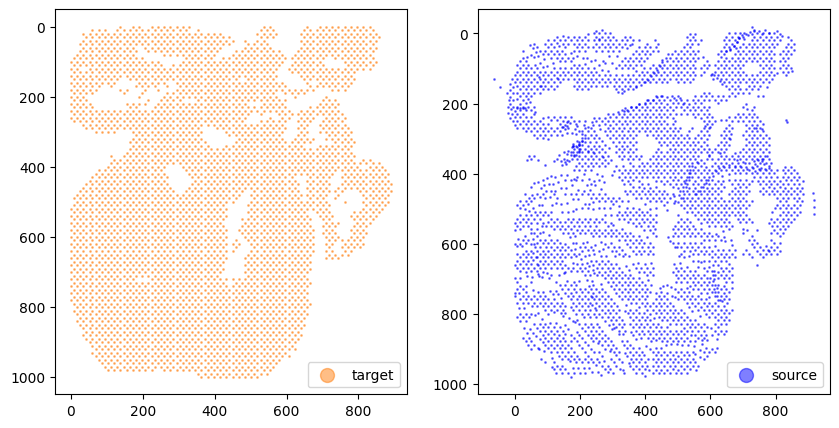

In [ ]:
# xI = queryAD.obs['spot_x'].values/10
# yI = queryAD.obs['spot_y'].values/10
# xJ = refAD.obs['spot_x'].values/10
# yJ = refAD.obs['spot_y'].values/10

xI = queryAD.obs['New_X'].values
yI = queryAD.obs['New_Y'].values
xJ = refAD.obs['New_X'].values
yJ = refAD.obs['New_Y'].values
xJ = xJ.astype(int)
yJ = yJ.astype(int)
xI = xI.astype(int)
yI = yI.astype(int)
import matplotlib.pyplot as plt
fig,ax = plt.subplots(1,2, figsize=(10, 5))

ax[0].scatter(xJ,yJ,s=1,alpha=0.5,c='#ff7f0e', label='target')
ax[1].scatter(xI,yI,s=1,alpha=0.5,c='blue', label='source')
ax[0].legend(markerscale = 10)
ax[1].legend(markerscale = 10)
ax[0].invert_yaxis()
ax[1].invert_yaxis()





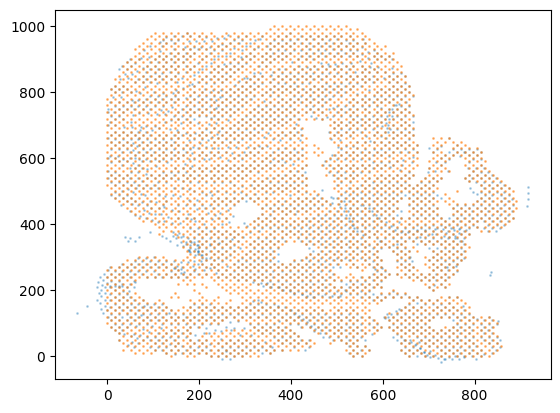

In [4]:
# plot
fig,ax = plt.subplots()
ax.scatter(xI,yI,s=1,alpha=0.3)
ax.scatter(xJ,yJ,s=1,alpha=0.5)

In [5]:
cols = [
    'Smooth muscle cells_percentage',
    'Fibroblast_percentage',
    'Atrial cardiomyocytes_percentage',
    'Cardiomyocytes_percentage',
    'Endothelium_percentage',
    'Epicardium_percentage',
    'Schwan progenitors_percentage',
    'Ventricular cardiomyocytes_percentage'
]
sJ = refAD.X
sI = queryAD.X



In [6]:
sI.shape

(3184, 67)

In [7]:
refAD.shape

(3801, 67)

0 of 3801
100 of 3801
200 of 3801
300 of 3801
400 of 3801
500 of 3801
600 of 3801
700 of 3801
800 of 3801
900 of 3801
1000 of 3801
1100 of 3801
1200 of 3801
1300 of 3801
1400 of 3801
1500 of 3801
1600 of 3801
1700 of 3801
1800 of 3801
1900 of 3801
2000 of 3801
2100 of 3801
2200 of 3801
2300 of 3801
2400 of 3801
2500 of 3801
2600 of 3801
2700 of 3801
2800 of 3801
2900 of 3801
3000 of 3801
3100 of 3801
3200 of 3801
3300 of 3801
3400 of 3801
3500 of 3801
3600 of 3801
3700 of 3801
3800 of 3801
0 of 3184
100 of 3184
200 of 3184
300 of 3184
400 of 3184
500 of 3184
600 of 3184
700 of 3184
800 of 3184
900 of 3184
1000 of 3184
1100 of 3184
1200 of 3184
1300 of 3184
1400 of 3184
1500 of 3184
1600 of 3184
1700 of 3184
1800 of 3184
1900 of 3184
2000 of 3184
2100 of 3184
2200 of 3184
2300 of 3184
2400 of 3184
2500 of 3184
2600 of 3184
2700 of 3184
2800 of 3184
2900 of 3184
3000 of 3184
3100 of 3184
3183 of 3184


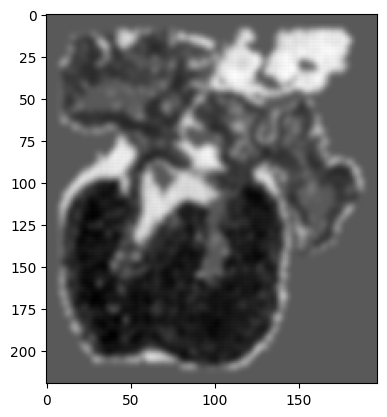

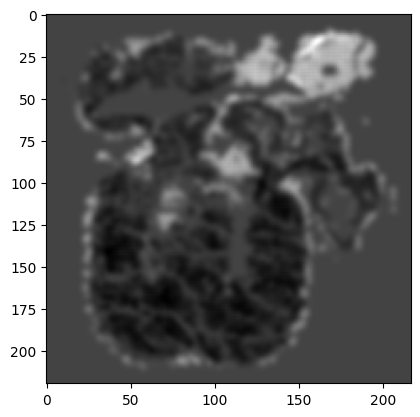

In [ ]:

sc.tl.pca(refAD, n_comps=4)
sc.tl.pca(queryAD, n_comps=4)

XJ,YJ,J,fig = STalign.rasterize_with_signal(xJ,yJ,refAD.obsm['X_pca'],dx=5, draw=100)
XI,YI,I,fig = STalign.rasterize_with_signal(xI,yI,queryAD.obsm['X_pca'],dx=5, draw=100)


In [17]:
XJ.shape, J.shape, I.max()

((197,), (4, 220, 197), 1.0)

In [18]:
# Min-max normalize I and J to 0-1
I = (I - I.min()) / (I.max() - I.min())
J = (J - J.min()) / (J.max() - J.min())


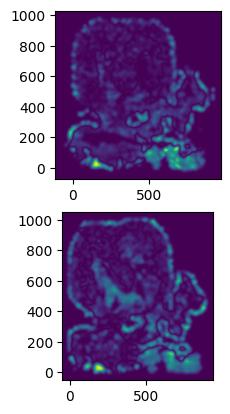

In [19]:
# get extent of images
extentI = STalign.extent_from_x((YI,XI))
extentJ = STalign.extent_from_x((YJ,XJ))

# plot rasterized images
ix = 2
fig,ax = plt.subplots(2,1)
I_sub = I[ix,:,:].squeeze()
J_sub = J[ix,:,:].squeeze()
ax[0].imshow(I_sub, extent=extentI)
ax[1].imshow(J_sub, extent=extentJ)
ax[0].invert_yaxis()
ax[1].invert_yaxis()

In [20]:
import torch # set device for building tensors
if torch.cuda.is_available():
    torch.set_default_device('cuda:0')
else:
    torch.set_default_device('cpu')

torch.cuda.is_available()

True

In [40]:
#from STalignLDDMM import LDDMM
from STalign.STalign import LDDMM

/home/adyprat/anaconda3/envs/spatial/lib/python3.8/site-packages/torch/utils/_device.py:62: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return func(*args, **kwargs)
/home/adyprat/anaconda3/envs/spatial/lib/python3.8/site-packages/STalign/STalign.py:1301: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  axE[2].set_yscale('log')


CPU times: user 1min 3s, sys: 1.59 s, total: 1min 5s
Wall time: 41 s


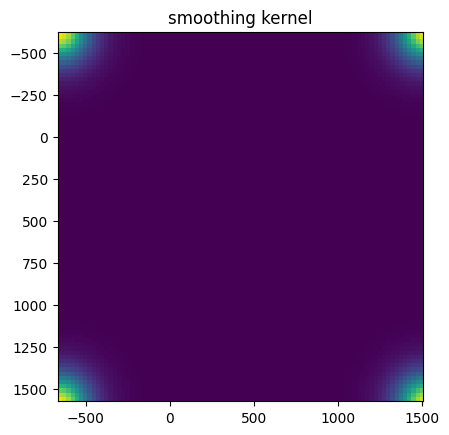

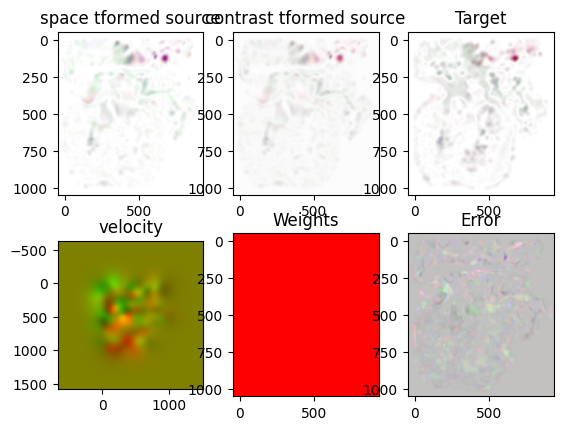

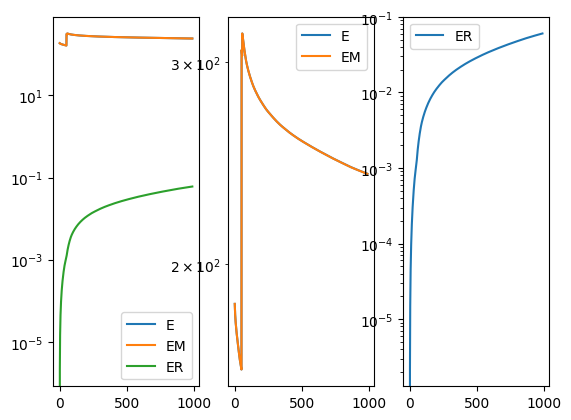

In [42]:
%%time
import numpy as np

# run LDDMM
# specify device (default device for STalign.LDDMM is cpu)
if torch.cuda.is_available():
    device = 'cuda:0'
else:
    device = 'cpu'

# keep all other parameters default
params = {
          'niter':1000,
          'device':device,
          'diffeo_start':0,
          'a':50,
          'epV':1000,
          #'muB': torch.tensor([0,0,0]), # black is background in target
          }
ix = 2
Ifoo = np.vstack((I[ix,:,:][None, ...], I[ix,:,:][None, ...], I[ix,:,:][None, ...])) # make RGB instead of greyscale
Jfoo = np.vstack((J[ix,:,:][None, ...], J[ix,:,:][None, ...], J[ix,:,:][None, ...])) # make RGB instead of greyscale

Ifoo = I # make RGB instead of greyscale
Jfoo = J # make RGB instead of greyscale
out = LDDMM([YI,XI],Ifoo,[YJ,XJ],Jfoo,**params)

In [43]:
I[1:4,:,:].shape

(3, 220, 217)

In [44]:
# get necessary output variables
A = out['A']
v = out['v']
xv = out['xv']

/home/adyprat/anaconda3/envs/spatial/lib/python3.8/site-packages/torch/utils/_device.py:62: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return func(*args, **kwargs)
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


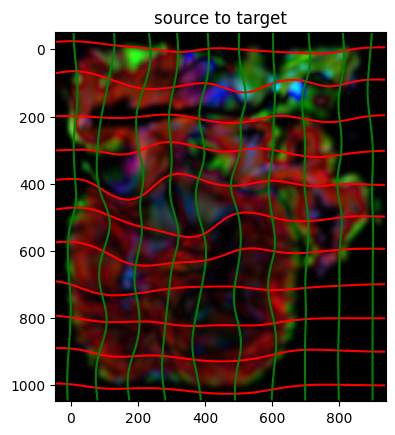

In [59]:
# apply transform
phii = STalign.build_transform(xv,v,A,XJ=[YJ,XJ],direction='b')
phiI = STalign.transform_image_source_to_target(xv,v,A,[YI,XI],Ifoo,[YJ,XJ])

#switch tensor from cuda to cpu for plotting with numpy
if phii.is_cuda:
    phii = phii.cpu()
if phiI.is_cuda:
    phiI = phiI.cpu()

# plot with grids
fig,ax = plt.subplots()
levels = np.arange(-10000,10000,100)
ax.contour(XJ,YJ,phii[...,0],colors='r',linestyles='-',levels=levels)
ax.contour(XJ,YJ,phii[...,1],colors='g',linestyles='-',levels=levels)
ax.set_aspect('equal')
ax.set_title('source to target')
ax.imshow(2*phiI[1:4,:,:].permute(1,2,0)/torch.max(phiI),extent=extentJ)

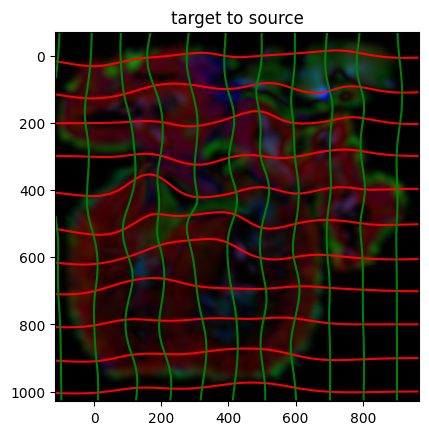

In [46]:
# apply transform
phij = STalign.build_transform(xv,v,A,XJ=[YI,XI],direction='f')
phijJ = STalign.transform_image_target_to_source(xv,v,A,[YI,XI],Jfoo,[YI,XI])

#switch tensor from cuda to cpu for plotting with numpy
if phij.is_cuda:
    phij = phij.cpu()
if phijJ.is_cuda:
    phijJ = phijJ.cpu()

# plot with grids
fig,ax = plt.subplots()
levels = np.arange(-10000,10000,100)
ax.contour(XI,YI,phij[...,0],colors='r',linestyles='-',levels=levels)
ax.contour(XI,YI,phij[...,1],colors='g',linestyles='-',levels=levels)
ax.set_aspect('equal')
ax.set_title('target to source')
ax.imshow(phijJ[1:4,:,:].permute(1,2,0)/torch.max(phijJ),extent=extentI)

In [47]:
xv_int = [t.to(torch.int) for t in xv]
xv_int

[tensor([-616, -591, -566, -541, -516, -491, -466, -441, -416, -391, -366, -341,
         -316, -291, -266, -241, -216, -191, -166, -141, -116,  -91,  -66,  -41,
          -16,    8,   33,   58,   83,  108,  133,  158,  183,  208,  233,  258,
          283,  308,  333,  358,  383,  408,  433,  458,  483,  508,  533,  558,
          583,  608,  633,  658,  683,  708,  733,  758,  783,  808,  833,  858,
          883,  908,  933,  958,  983, 1008, 1033, 1058, 1083, 1108, 1133, 1158,
         1183, 1208, 1233, 1258, 1283, 1308, 1333, 1358, 1383, 1408, 1433, 1458,
         1483, 1508, 1533, 1558], device='cuda:0', dtype=torch.int32),
 tensor([-654, -629, -604, -579, -554, -529, -504, -479, -454, -429, -404, -379,
         -354, -329, -304, -279, -254, -229, -204, -179, -154, -129, -104,  -79,
          -54,  -29,   -4,   20,   45,   70,   95,  120,  145,  170,  195,  220,
          245,  270,  295,  320,  345,  370,  395,  420,  445,  470,  495,  520,
          545,  570,  595,  620,  645,

In [48]:
# Ensure input types match grid types (FloatTensor, not DoubleTensor)
points_np = np.stack([yJ, xJ], 1).astype(np.float32)
points_tensor = torch.from_numpy(points_np).to(xv[0].device).type(xv[0].dtype)
tpointsJ  = STalign.transform_points_target_to_source(xv_int,v,A, points_tensor)


#switch from row column coordinates (y,x) to (x,y)
xJ_LDDMM = tpointsJ[:,1]
yJ_LDDMM = tpointsJ[:,0]


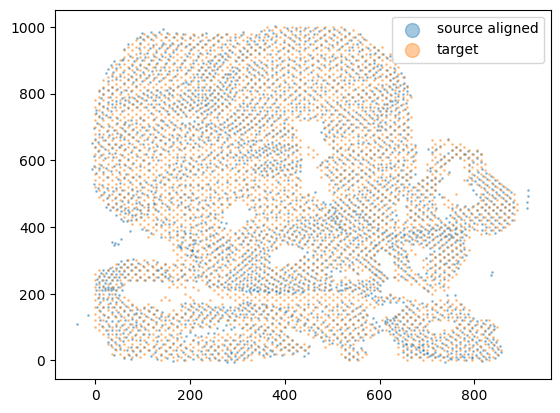

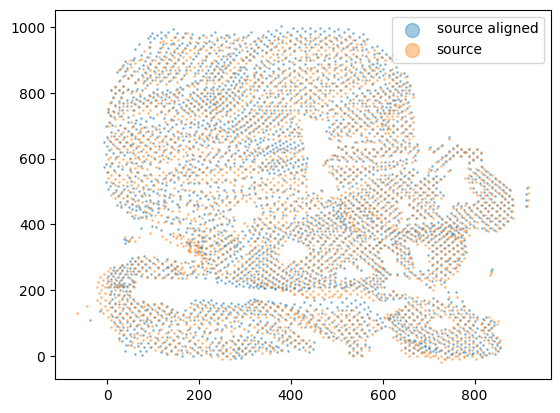

In [49]:


# Ensure input types match grid types (FloatTensor, not DoubleTensor)
points_np = np.stack([yI, xI], 1).astype(np.float32)
points_tensor = torch.from_numpy(points_np).to(xv[0].device).type(xv[0].dtype)
tpointsI = STalign.transform_points_source_to_target(
    xv, v, A, points_tensor, 
)

#switch tensor from cuda to cpu for plotting with numpy
if tpointsI.is_cuda:
    tpointsI = tpointsI.cpu()

#switch from row column coordinates (y,x) to (x,y)
xI_LDDMM = tpointsI[:,1]
yI_LDDMM = tpointsI[:,0]

# plot results
fig,ax = plt.subplots()
#ax.scatter(xJ,yJ,s=1,alpha=0.3, label='source')
ax.scatter(xI_LDDMM,yI_LDDMM,s=1,alpha=0.4, label = 'source aligned')
ax.scatter(xJ,yJ,s=1,alpha=0.4, label='target')
ax.legend(markerscale = 10)

fig,ax = plt.subplots()
ax.scatter(xI_LDDMM,yI_LDDMM,s=1,alpha=0.4, label='source aligned')
ax.scatter(xI,yI,s=1,alpha=0.4, label='source')
ax.legend(markerscale = 10)

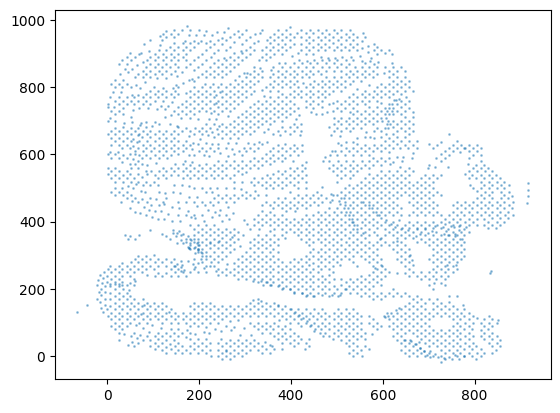

In [50]:
plt.scatter(xI,yI,s=1,alpha=0.4, label = 'source aligned')


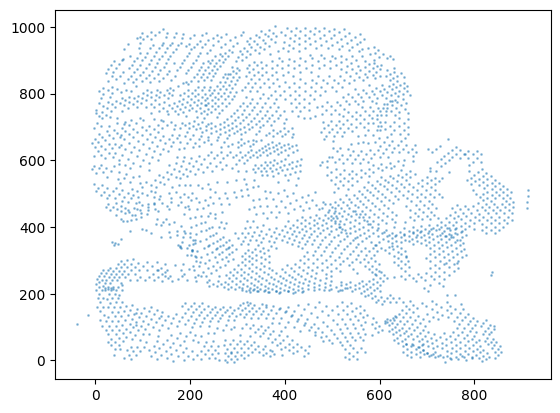

In [51]:
plt.scatter(xI_LDDMM,yI_LDDMM,s=1,alpha=0.4, label = 'source aligned')


In [52]:
xJ.shape

(3801,)

In [53]:
xJ_LDDMM.shape

torch.Size([3801])

In [54]:
queryAD

AnnData object with n_obs × n_vars = 3184 × 67
    obs: 'spot_x', 'spot_y', 'cell_count', 'Smooth muscle cells_percentage', 'Fibroblast_percentage', 'Atrial cardiomyocytes_percentage', 'Cardiomyocytes_percentage', 'Endothelium_percentage', 'Epicardium_percentage', 'Schwan progenitors_percentage', 'Ventricular cardiomyocytes_percentage', 'Cell_Num', 'New_X', 'New_Y', 'STAlign_X', 'STAlign_Y', 'CellType', 'NearestRefCellType', 'CellTypeMatch'
    var: 'mean', 'std'
    uns: 'log1p', 'pca'
    obsm: 'X_spatial', 'spatial', 'X_pca'
    varm: 'PCs'

In [55]:
queryAD.obs.loc[:, 'STAlign_X'] = xI_LDDMM
queryAD.obs.loc[:, 'STAlign_Y'] = yI_LDDMM

# Remove '_percentage' to get cell type names
cell_types = [col.replace('_percentage', '') for col in cols]

# Find the column with the maximum value for each row and assign as 'Ground Truth'
queryAD.obs['CellType'] = queryAD.obs[cols].idxmax(axis=1).str.replace('_percentage', '').astype('category')
refAD.obs['CellType'] = refAD.obs[cols].idxmax(axis=1).str.replace('_percentage', '').astype('category')



In [56]:
queryAD

AnnData object with n_obs × n_vars = 3184 × 67
    obs: 'spot_x', 'spot_y', 'cell_count', 'Smooth muscle cells_percentage', 'Fibroblast_percentage', 'Atrial cardiomyocytes_percentage', 'Cardiomyocytes_percentage', 'Endothelium_percentage', 'Epicardium_percentage', 'Schwan progenitors_percentage', 'Ventricular cardiomyocytes_percentage', 'Cell_Num', 'New_X', 'New_Y', 'STAlign_X', 'STAlign_Y', 'CellType', 'NearestRefCellType', 'CellTypeMatch'
    var: 'mean', 'std'
    uns: 'log1p', 'pca'
    obsm: 'X_spatial', 'spatial', 'X_pca'
    varm: 'PCs'

In [57]:
import numpy as np

# Assuming refAD is your reference AnnData object with 'spot_x', 'spot_y', and 'CellType' in .obs
# and queryAD is your query AnnData object with 'STAlign_X', 'STAlign_Y', and 'CellType' in .obs

# Get coordinates from refAD and queryAD
ref_coords = refAD.obs[['New_X', 'New_Y']].values
query_coords = queryAD.obs[['STAlign_X', 'STAlign_Y']].values

# Get cell types
ref_celltypes = refAD.obs['CellType'].values
query_celltypes = queryAD.obs['CellType'].values

# For each query cell, find the nearest ref cell and compare CellType
from scipy.spatial import cKDTree

tree = cKDTree(ref_coords)
dists, idxs = tree.query(query_coords, k=1)

# Compare cell types
matches = query_celltypes == ref_celltypes[idxs]

# Optionally, print or summarize the results
print(f"Number of matches: {np.sum(matches)} / {len(matches)}")
print(f"Match percentage: {np.mean(matches)*100:.2f}%")

# If you want to see which ones matched/mismatched:
queryAD.obs['NearestRefCellType'] = ref_celltypes[idxs]
queryAD.obs['CellTypeMatch'] = matches


Number of matches: 1886 / 3184
Match percentage: 59.23%


In [58]:
queryAD.obsm['X_STAlign_spatial'] = queryAD.obs[['STAlign_X', 'STAlign_Y']].values
queryAD.write_h5ad('query_STAlign.h5ad')

refAD.obsm['X_STAlign_spatial'] = refAD.obs[['New_X', 'New_Y']].values
refAD.write_h5ad('ref_STAlign.h5ad')




